# Gaussian RollBack SMC: five terminal levels at equal native-transition cost

This notebook runs independently in Google Colab with **Run all**; it imports no local files. Select a GPU runtime if desired. The comparison budget is always **used native Gaussian transitions**, not wall clock. The notebook also runs on CPU.

One complete SMC run uses $N=128$, $T=16$, $x_T=0$, and native transitions $N(x_t,1/T)$. The five SMC levels have current tilt $\lambda=1,2,3,4,5$ (starting at $0$), with one RollBack–MH move per level and independent uniform depth $d\in\{1,\dots,16\}$ per particle. At each level: weighting, systematic resampling if ESS/$N<0.5$ for the continuing population, then mutation. A separate copy after weighting is mutated without resampling to give the estimator that would result if the run stopped at that level. At level 5, the main population is terminal and receives no final resampling.

For $A=\{x_0\ge a\}$, $a$ is the *theoretical* normal inverse-survival quantile for $p_A\in\{10^{-3},10^{-4},10^{-5}\}$. The two estimators from the same terminal population are

$$\widehat p_{A}^{SMC}=\widehat Z\sum_i\overline W_i e^{-\lambda\Phi(\tau_i)}\mathbf 1_A(\tau_i),\qquad
\widehat p_{A}^{SNIS}=\frac{\sum_i\overline W_i e^{-\lambda\Phi(\tau_i)}\mathbf 1_A(\tau_i)}{\sum_i\overline W_i e^{-\lambda\Phi(\tau_i)}}.$$

The current level's $\lambda$ is used in each correction. The five estimates within a run are correlated and are never averaged together. For each level, crude MC generates $\lfloor B/16\rfloor$ complete native trajectories where $B$ counts $128\times16$ initial transitions plus **all suffix proposal transitions**, including rejected proposals, along the SMC pipeline ending at that level. The cost of other terminal copies is excluded. GPU padding draws are recorded separately.

In [1]:
# Standard Colab packages; install only if unavailable.
import importlib.util, subprocess, sys
missing = [name for name in ('numpy', 'pandas', 'scipy', 'matplotlib', 'torch', 'nbformat') if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
print('Dependencies ready; GPU is optional.')

Dependencies ready; GPU is optional.


In [2]:
"""Five-level Gaussian RollBack SMC; embedded verbatim in the standalone notebook."""
import math
import time
import numpy as np
import torch
from scipy.stats import norm

T = 16
N = 128
LEVELS = (1, 2, 3, 4, 5)
P_EVENTS = (1e-3, 1e-4, 1e-5)
THRESHOLDS = tuple(float(norm.isf(p)) for p in P_EVENTS)
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32 if DEVICE.type == "cuda" else torch.float64


def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)


def seed_for(main_seed, run, stream, level=0):
    seq = np.random.SeedSequence([main_seed, run, stream, level])
    return int(seq.generate_state(1, dtype=np.uint64)[0] % np.uint64(2**63 - 1))


def rng_for(seed):
    return torch.Generator(device=DEVICE).manual_seed(int(seed))


@torch.inference_mode()
def native_paths(count, rng):
    steps = torch.randn((count, T), generator=rng, device=DEVICE, dtype=DTYPE) / math.sqrt(T)
    return torch.cat((torch.zeros((count, 1), device=DEVICE, dtype=DTYPE), steps.cumsum(1)), 1)


@torch.inference_mode()
def rollback_M_k(paths, current_lambda, rng):
    count = len(paths)
    depths = torch.randint(1, T + 1, (count,), generator=rng, device=DEVICE)
    cut = T - depths
    mask = torch.arange(T, device=DEVICE)[None, :] >= cut[:, None]
    # CUDA-friendly padding: T Gaussian draws per proposal; only d enter the suffix.
    steps = torch.randn((count, T), generator=rng, device=DEVICE, dtype=DTYPE) / math.sqrt(T)
    proposed_suffix = paths.gather(1, cut[:, None]) + torch.where(mask, steps, 0).cumsum(1)
    proposed = torch.cat((paths[:, :1], torch.where(mask, proposed_suffix, paths[:, 1:])), 1)
    log_accept = torch.minimum(torch.zeros((), device=DEVICE, dtype=DTYPE),
                               current_lambda * (proposed[:, -1] - paths[:, -1]))
    accept = torch.log(torch.rand(count, generator=rng, device=DEVICE, dtype=DTYPE)) < log_accept
    return torch.where(accept[:, None], proposed, paths), depths, accept


@torch.inference_mode()
def systematic(log_weights, rng, offset=None):
    count = len(log_weights)
    cumulative = log_weights.exp().cumsum(0)
    cumulative[-1] = 1
    if offset is None:
        offset = torch.rand((), generator=rng, device=DEVICE, dtype=DTYPE)
    points = (torch.arange(count, device=DEVICE, dtype=DTYPE) + offset) / count
    return torch.searchsorted(cumulative, points)


@torch.inference_mode()
def diagnostics(paths, log_weights, log_z, roots, current_lambda):
    x = paths[:, -1]
    n = len(paths)
    reverse_log = log_weights - current_lambda * x
    reverse_norm = reverse_log - torch.logsumexp(reverse_log, 0)
    threshold = torch.tensor(THRESHOLDS, device=DEVICE, dtype=DTYPE)
    hits = x[:, None] >= threshold[None, :]
    numerators = torch.logsumexp(torch.where(hits, reverse_log[:, None], -torch.inf), 0)
    smc = torch.exp(log_z + numerators)
    snis = torch.exp(numerators - torch.logsumexp(reverse_log, 0))
    return {
        "smc": smc.cpu().numpy().tolist(), "snis": snis.cpu().numpy().tolist(),
        "event_particles": hits.sum(0).cpu().numpy().tolist(),
        "ess_after": float(torch.exp(-torch.logsumexp(2 * log_weights, 0)).item() / n),
        "reverse_ess": float(torch.exp(-torch.logsumexp(2 * reverse_norm, 0)).item() / n),
        "reverse_max": float(reverse_norm.max().exp().item()),
        "ancestors": int(torch.unique(roots).numel()),
        "weighted_x": float((log_weights.exp() * x).sum().item()),
        "z_hat": float(log_z.exp().item()),
        "reverse_identity": float(torch.exp(log_z + torch.logsumexp(reverse_log, 0)).item()),
    }


@torch.inference_mode()
def run_five_levels(main_seed, run, record_debug=False):
    """One run, five separate terminal estimators, and one cumulative crude baseline."""
    rng = rng_for(seed_for(main_seed, run, 0))
    sync(); start = time.perf_counter()
    paths = native_paths(N, rng)
    log_weights = torch.full((N,), -math.log(N), device=DEVICE, dtype=DTYPE)
    log_z = torch.zeros((), device=DEVICE, dtype=DTYPE)
    roots = torch.arange(N, device=DEVICE)
    used_main = N * T
    padded_main = N * T
    used_copies = 0
    padded_copies = 0
    copy_seconds = 0.0
    rows = []
    traces = []
    for level in LEVELS:
        before = (paths.clone(), log_weights.clone(), log_z.clone(), roots.clone()) if record_debug else None
        unnormalized = log_weights + (level - (level - 1)) * paths[:, -1]
        increment = torch.logsumexp(unnormalized, 0)
        log_z = log_z + increment
        log_weights = unnormalized - increment
        ess_before = float(torch.exp(-torch.logsumexp(2 * log_weights, 0)).item() / N)
        weighted = (paths.clone(), log_weights.clone(), roots.clone()) if record_debug else None
        if level < LEVELS[-1]:
            # Terminal copy: mutation at this temperature, no final resampling.
            copy_rng = rng_for(seed_for(main_seed, run, 1, level))
            sync(); copy_start = time.perf_counter()
            terminal_paths, terminal_depths, _ = rollback_M_k(paths, level, copy_rng)
            terminal = diagnostics(terminal_paths, log_weights, log_z, roots, level)
            sync(); copy_elapsed = time.perf_counter() - copy_start
            copy_seconds += copy_elapsed
            copy_used = int(terminal_depths.sum().item())
            used_copies += copy_used
            padded_copies += N * T
            terminal_budget = used_main + copy_used
            terminal_padding = padded_main + N * T
            terminal_time = time.perf_counter() - start - copy_seconds + copy_elapsed
            # Continuing population: systematic selection only if ESS/N < 0.5.
            resampled = ess_before < .5
            if resampled:
                parent = systematic(log_weights, rng)
                paths = paths.index_select(0, parent)
                roots = roots.index_select(0, parent)
                log_weights = torch.full_like(log_weights, -math.log(N))
            ess_after_resampling = float(torch.exp(-torch.logsumexp(2 * log_weights, 0)).item() / N)
            paths, depths, _ = rollback_M_k(paths, level, rng)
            used_main += int(depths.sum().item())
            padded_main += N * T
        else:
            # At the last level the main population itself is terminal: no resampling.
            resampled = False
            ess_after_resampling = ess_before
            paths, depths, _ = rollback_M_k(paths, level, rng)
            used_main += int(depths.sum().item())
            padded_main += N * T
            terminal = diagnostics(paths, log_weights, log_z, roots, level)
            terminal_budget = used_main
            terminal_padding = padded_main
            sync(); terminal_time = time.perf_counter() - start - copy_seconds
        record = {
            "main_seed": main_seed, "run": run, "level": level, "lambda": level,
            "ess_before": ess_before, "ess_after_resampling": ess_after_resampling,
            "resampled_main": resampled, "budget_transitions": terminal_budget,
            "padded_gaussian_draws": terminal_padding,
            "main_used_transitions": used_main,
            "diagnostic_copy_transitions_cumulative": used_copies,
            "diagnostic_copy_padded_draws_cumulative": padded_copies,
            "diagnostic_copy_seconds_cumulative": copy_seconds,
            "estimated_terminal_seconds": terminal_time,
            **{k: v for k, v in terminal.items() if k not in ("smc", "snis", "event_particles")},
        }
        for j, p_true in enumerate(P_EVENTS):
            rows.append({**record, "p_A": p_true, "smc": terminal["smc"][j],
                         "snis": terminal["snis"][j], "event_particles": terminal["event_particles"][j]})
        if record_debug:
            traces.append({"level": level, "before": before, "weighted": weighted,
                           "increment": increment.clone(), "terminal_paths":
                           terminal_paths.clone() if level < LEVELS[-1] else paths.clone(),
                           "terminal_depths": terminal_depths.clone() if level < LEVELS[-1] else depths.clone(),
                           "terminal": terminal.copy(), "record": record.copy()})
    # Independent native crude sample; prefixes are reused across levels within this run.
    crude_rng = rng_for(seed_for(main_seed, run, 2))
    crude_counts = [row["budget_transitions"] // T for row in rows[::len(P_EVENTS)]]
    crude_paths = native_paths(max(crude_counts), crude_rng)
    crude_hits = (crude_paths[:, -1, None] >= torch.tensor(THRESHOLDS, device=DEVICE, dtype=DTYPE)).to(torch.int32)
    crude_cumulative = crude_hits.cumsum(0)
    for level_index, count in enumerate(crude_counts):
        hits = crude_cumulative[count - 1].cpu().numpy()
        for event_index in range(len(P_EVENTS)):
            rows[level_index * len(P_EVENTS) + event_index]["crude"] = float(hits[event_index] / count)
            rows[level_index * len(P_EVENTS) + event_index]["crude_n"] = count
            rows[level_index * len(P_EVENTS) + event_index]["crude_transitions"] = count * T
    return rows, traces


In [3]:
"""Tests, 5,000 independent replications, tables and plots for five terminal tilts."""
import json
import math
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.stats import norm

MAIN_SEEDS = (20261001, 20261002, 20261003, 20261004, 20261005)
RUNS_PER_SEED = 1000
OUT = Path("five_level_results")


def verify():
    assert (T, N, LEVELS) == (16, 128, (1, 2, 3, 4, 5))
    np.testing.assert_allclose(THRESHOLDS, norm.isf(P_EVENTS), rtol=0, atol=1e-14)
    paths = native_paths(100000, rng_for(100))
    assert abs(float(paths[:, -1].mean())) < .012
    assert abs(float(paths[:, -1].var()) - 1) < .02
    # Exact tilted trajectory: increments have mean lambda/T, x_0 ~ N(lambda,1).
    current_lambda = 2
    tilted = paths + (torch.arange(T + 1, device=DEVICE, dtype=DTYPE) * current_lambda / T)
    moved, depths, _ = rollback_M_k(tilted, current_lambda, rng_for(101))
    counts = torch.bincount(depths, minlength=T + 1)[1:].cpu().numpy()
    assert np.max(abs(counts - len(paths) / T)) / (len(paths) / T) < .06
    cut = T - depths
    assert torch.all(torch.where(torch.arange(T + 1, device=DEVICE)[None, :] <= cut[:, None],
                                 moved == tilted, True))
    assert abs(float(moved[:, -1].mean()) - current_lambda) < .025
    assert abs(float(moved[:, -1].var()) - 1) < .025
    weights = torch.tensor([.05, .35, .10, .50], device=DEVICE, dtype=DTYPE)
    offset = torch.tensor(.37, device=DEVICE, dtype=DTYPE)
    np.testing.assert_array_equal(systematic(weights.log(), rng_for(102), offset).cpu().numpy(),
                                  np.searchsorted(np.cumsum(weights.cpu().numpy()),
                                                  (np.arange(4) + .37) / 4))
    rows, traces = run_five_levels(MAIN_SEEDS[0], 99999, record_debug=True)
    assert len(rows) == len(LEVELS) * len(P_EVENTS)
    assert any(t["record"]["resampled_main"] for t in traces[:-1])
    assert any(not t["record"]["resampled_main"] for t in traces)
    assert not traces[-1]["record"]["resampled_main"]
    for trace in traces:
        level = trace["level"]
        before_paths, before_w, before_z, before_roots = trace["before"]
        weighted_paths, weighted_w, weighted_roots = trace["weighted"]
        expected = before_w + before_paths[:, -1]
        log_inc = torch.logsumexp(expected, 0)
        torch.testing.assert_close(log_inc, trace["increment"])
        torch.testing.assert_close(weighted_w, expected - log_inc)
        torch.testing.assert_close(weighted_paths, before_paths)
        torch.testing.assert_close(weighted_roots, before_roots)
        z = float((before_z + log_inc).exp())
        assert math.isclose(z, trace["terminal"]["z_hat"], rel_tol=2e-6)
        ess = float(torch.exp(-torch.logsumexp(2 * weighted_w, 0)) / N)
        assert abs(ess - trace["record"]["ess_before"]) < 1e-7
        assert trace["record"]["resampled_main"] == (level < 5 and ess < .5)
        x = trace["terminal_paths"][:, -1].cpu().numpy()
        w = weighted_w.exp().cpu().numpy()
        reverse = w * np.exp(-level * x)
        reverse_norm = reverse / reverse.sum()
        assert np.isclose(trace["terminal"]["reverse_ess"], 1 / (N * np.sum(reverse_norm**2)), rtol=2e-6)
        assert np.isclose(trace["terminal"]["reverse_identity"], z * reverse.sum(), rtol=2e-6)
        for j, threshold in enumerate(THRESHOLDS):
            numerator = np.sum(reverse * (x >= threshold))
            assert np.isclose(trace["terminal"]["smc"][j], z * numerator, rtol=2e-6, atol=1e-12)
            assert np.isclose(trace["terminal"]["snis"][j], numerator / reverse.sum(), rtol=2e-6, atol=1e-12)
        previous_main = N*T if level == 1 else traces[level-2]["record"]["main_used_transitions"]
        assert trace["record"]["budget_transitions"] == previous_main + int(trace["terminal_depths"].sum())
    for row in rows:
        assert row["crude_n"] == row["budget_transitions"] // T
        assert row["crude_transitions"] <= row["budget_transitions"]
        assert row["p_A"] in P_EVENTS
    return {"device": str(DEVICE), "torch": torch.__version__,
            "depth_counts_min": int(counts.min()), "depth_counts_max": int(counts.max()),
            "test_resampled_levels": [t["level"] for t in traces if t["record"]["resampled_main"]],
            "test_no_resample_levels": [t["level"] for t in traces if not t["record"]["resampled_main"]],
            "terminal_no_resampling": True}


def one_summary(values, p_true):
    values = np.asarray(values, dtype=float)
    errors = values - p_true
    squared = errors**2
    rmse = math.sqrt(float(squared.mean()))
    return {"mean": float(values.mean()), "bias": float(errors.mean()),
            "bias_mc_se": float(values.std(ddof=1) / math.sqrt(len(values))),
            "variance": float(values.var(ddof=1)), "rmse": rmse,
            "rmse_mc_se": float(squared.std(ddof=1) / (2 * math.sqrt(len(values)) * rmse)) if rmse else 0,
            "zero_fraction": float(np.mean(values == 0))}


def summarize(frame, group_columns=("level", "p_A")):
    records = []
    for keys, group in frame.groupby(list(group_columns), sort=True):
        key = dict(zip(group_columns, keys if isinstance(keys, tuple) else (keys,)))
        p_true = key["p_A"]
        for estimator in ("smc", "snis", "crude"):
            record = {**key, "estimator": estimator, "runs": len(group),
                      **one_summary(group[estimator], p_true),
                      "budget_transitions_mean": float(group.budget_transitions.mean()),
                      "budget_transitions_min": int(group.budget_transitions.min()),
                      "budget_transitions_max": int(group.budget_transitions.max()),
                      "crude_n_mean": float(group.crude_n.mean()),
                      "crude_theoretical_rmse": float(np.sqrt(
                          np.mean(p_true * (1-p_true) / group.crude_n.to_numpy()))),
                      "event_particles_mean": float(group.event_particles.mean())}
            records.append(record)
    return pd.DataFrame(records)


def diagnostic_summary(frame):
    base = frame[frame.p_A == P_EVENTS[0]]
    metrics = ("ess_before", "ess_after_resampling", "ess_after", "reverse_ess",
               "reverse_max", "ancestors", "weighted_x", "z_hat", "reverse_identity",
               "budget_transitions", "diagnostic_copy_transitions_cumulative",
               "estimated_terminal_seconds")
    rows = []
    for level, group in base.groupby("level"):
        for metric in metrics:
            v = group[metric]
            rows.append({"level": level, "metric": metric, "mean": float(v.mean()),
                         "mean_mc_se": float(v.std(ddof=1) / math.sqrt(len(v))),
                         "median": float(v.median()), "p05": float(v.quantile(.05)),
                         "p95": float(v.quantile(.95)), "minimum": float(v.min()),
                         "maximum": float(v.max()), "theory":
                         math.exp(level**2/2) if metric == "z_hat" else
                         float(level) if metric == "weighted_x" else
                         1.0 if metric == "reverse_identity" else np.nan})
        rows.append({"level": level, "metric": "resampling_rate", "mean": float(group.resampled_main.mean())})
    return pd.DataFrame(rows)


def diagnostic_by_seed(frame):
    base = frame[frame.p_A == P_EVENTS[0]]
    columns = ("ess_before", "ess_after_resampling", "reverse_ess", "reverse_max",
               "ancestors", "weighted_x", "z_hat", "reverse_identity",
               "budget_transitions", "diagnostic_copy_transitions_cumulative")
    grouped = base.groupby(["main_seed", "level"])[list(columns)].agg(["mean", "median"])
    grouped.columns = [f"{metric}_{statistic}" for metric, statistic in grouped.columns]
    return grouped.reset_index()


def plot_results(summary, diagnostics, out):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), constrained_layout=True)
    colors = {"smc": "#225ea8", "snis": "#d95f02", "crude": "#348a52"}
    for ax, p_true in zip(axes, P_EVENTS):
        group = summary[summary.p_A == p_true]
        for estimator in ("smc", "snis", "crude"):
            selected = group[group.estimator == estimator]
            ax.errorbar(selected.level, selected.rmse, yerr=1.96*selected.rmse_mc_se,
                        marker="o", color=colors[estimator], label=estimator, capsize=2)
        crude = group[group.estimator == "crude"]
        ax.plot(crude.level, crude.crude_theoretical_rmse, ":", color="black", label="crude theoretical")
        ax.set(xticks=LEVELS, xlabel="current λ", ylabel="RMSE", title=f"p_A={p_true:g}", yscale="log")
        ax.grid(alpha=.25)
    axes[0].legend(fontsize=8)
    fig.savefig(out / "rmse_equal_transitions.png", dpi=170)
    plt.close(fig)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), constrained_layout=True)
    base = diagnostics
    for metric, ax in zip(("ess_before", "reverse_ess", "weighted_x"), axes):
        group = base[base.metric == metric]
        ax.plot(group.level, group["median"], marker="o", label="median")
        ax.fill_between(group.level, group.p05, group.p95, alpha=.25, label="5–95%")
        if metric == "weighted_x": ax.plot(group.level, group.theory, ":", color="black", label="theory")
        ax.set(xticks=LEVELS, xlabel="current λ", title=metric)
        ax.grid(alpha=.25)
    axes[0].legend(fontsize=8)
    fig.savefig(out / "diagnostics.png", dpi=170)
    plt.close(fig)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), constrained_layout=True)
    z = diagnostics[diagnostics.metric == "z_hat"]
    axes[0].errorbar(z.level, z["mean"] / z.theory,
                     yerr=1.96*z.mean_mc_se / z.theory, marker="o", capsize=2)
    axes[0].axhline(1, color="black", linestyle=":")
    axes[0].set(title="mean normalizer / theoretical normalizer", xlabel="current λ", xticks=LEVELS)
    identity = diagnostics[diagnostics.metric == "reverse_identity"]
    axes[1].errorbar(identity.level, identity["mean"],
                     yerr=1.96*identity.mean_mc_se, marker="o", capsize=2)
    axes[1].axhline(1, color="black", linestyle=":")
    axes[1].set(title="mean reverse identity (target 1)", xlabel="current λ", xticks=LEVELS)
    for p_true in P_EVENTS:
        selected = summary[(summary.p_A == p_true) & (summary.estimator == "smc")]
        axes[2].plot(selected.level, selected.zero_fraction, marker="o", label=f"p_A={p_true:g}")
    axes[2].set(title="fraction of zero SMC/SNIS estimates", xlabel="current λ",
                ylabel="fraction", xticks=LEVELS, ylim=(0, 1.03))
    axes[2].legend(fontsize=8)
    for ax in axes: ax.grid(alpha=.25)
    fig.savefig(out / "weight_checks_and_zeros.png", dpi=170)
    plt.close(fig)


def run_study(out=OUT):
    out.mkdir(exist_ok=True, parents=True)
    checks = verify()
    (out / "checks.json").write_text(json.dumps(checks, indent=2), encoding="utf-8")
    # Warm GPU kernels, allocation and synchronization before recording runs.
    for j in range(8): run_five_levels(912345, j)
    sync(); start = time.perf_counter()
    all_rows = []
    for main_seed in MAIN_SEEDS:
        seed_rows = []
        for run in range(RUNS_PER_SEED):
            rows, _ = run_five_levels(main_seed, run)
            seed_rows.extend(rows)
            if (run + 1) % 250 == 0:
                print(f"main seed {main_seed}: {run+1}/{RUNS_PER_SEED}", flush=True)
        all_rows.extend(seed_rows)
        pd.DataFrame(seed_rows).to_csv(out / f"runs_seed_{main_seed}.csv", index=False)
    sync(); elapsed = time.perf_counter() - start
    frame = pd.DataFrame(all_rows)
    frame.to_csv(out / "runs.csv", index=False)
    summary = summarize(frame)
    summary.to_csv(out / "summary.csv", index=False)
    by_seed = summarize(frame, ("main_seed", "level", "p_A"))
    by_seed.to_csv(out / "summary_by_seed.csv", index=False)
    diagnostic = diagnostic_summary(frame)
    diagnostic.to_csv(out / "diagnostics.csv", index=False)
    seed_diagnostic = diagnostic_by_seed(frame)
    seed_diagnostic.to_csv(out / "diagnostics_by_seed.csv", index=False)
    plot_results(summary, diagnostic, out)
    parameters = {"T": T, "N": N, "levels": LEVELS, "p_A": P_EVENTS,
                  "thresholds": THRESHOLDS, "main_seeds": MAIN_SEEDS,
                  "runs_per_seed": RUNS_PER_SEED, "total_runs": len(MAIN_SEEDS)*RUNS_PER_SEED,
                  "device": str(DEVICE), "dtype": str(DTYPE), "seconds_total": elapsed,
                  "budget_rule": "floor(used_native_transitions / 16) complete crude trajectories",
                  "diagnostic_copy_cost_excluded_from_other_terminal_levels": True}
    (out / "parameters.json").write_text(json.dumps(parameters, indent=2), encoding="utf-8")
    print(f"Completed {len(MAIN_SEEDS)*RUNS_PER_SEED} independent runs in {elapsed:.1f}s on {DEVICE}.")
    print(summary[["level", "p_A", "estimator", "mean", "bias", "bias_mc_se",
                   "variance", "rmse", "rmse_mc_se", "zero_fraction",
                   "budget_transitions_mean", "crude_theoretical_rmse"]].to_string(index=False))
    return frame, summary, by_seed, diagnostic, parameters




## Verification before experiments

The tests check the native $x_0\sim N(0,1)$ marginal, theoretical event thresholds, uniform rollback depths and retained prefixes, one-step invariance of the RollBack–MH kernel under a known tilted Gaussian path law, systematic selection, the normalizer update with and without resampling, both reverse-correction formulas, transition budgets, and the absence of final resampling. A failed assertion stops **Run all** before the 5,000 runs.

In [4]:
checks = verify(); print(checks)

{'device': 'cpu', 'torch': '2.11.0+cpu', 'depth_counts_min': 6072, 'depth_counts_max': 6414, 'test_resampled_levels': [1, 2], 'test_no_resample_levels': [3, 4, 5], 'terminal_no_resampling': True}


## Independent full runs

Five recorded principal seeds, 1,000 independent runs each. Each run has independent random generators for its continuing SMC population, each diagnostic terminal copy, and crude MC. The same three events are evaluated from each population. Results are saved to CSV together with per-seed summaries.

In [5]:
runs, summary, summary_by_seed, diagnostic, parameters = run_study()

main seed 20261001: 250/1000


main seed 20261001: 500/1000


main seed 20261001: 750/1000


main seed 20261001: 1000/1000


main seed 20261002: 250/1000


main seed 20261002: 500/1000


... (11 outputs left out)

main seed 20261005: 500/1000


main seed 20261005: 750/1000


main seed 20261005: 1000/1000


Completed 5000 independent runs in 32.3s on cpu.
 level     p_A estimator     mean          bias  bias_mc_se     variance     rmse  rmse_mc_se  zero_fraction  budget_transitions_mean  crude_theoretical_rmse
     1 0.00001       smc 0.000011  1.008937e-06    0.000004 8.620810e-08 0.000294    0.000055         0.9984                3135.5740                0.000226
     1 0.00001      snis 0.000011  6.390761e-07    0.000004 8.061056e-08 0.000284    0.000054         0.9984                3135.5740                0.000226
     1 0.00001     crude 0.000017  7.275958e-06    0.000004 8.753542e-08 0.000296    0.000036         0.9966                3135.5740                0.000226
     1 0.00010       smc 0.000088 -1.200233e-05    0.000011 6.583509e-07 0.000811    0.000063         0.9808                3135.5740                0.000715
     1 0.00010      snis 0.000088 -1.159590e-05    0.000012 6.752818e-07 0.000822    0.000068         0.9808                3135.5740                0.000715
   

## Results and limitations

`summary.csv` reports mean, bias and Monte Carlo standard error, sample variance, RMSE and its Monte Carlo standard error, zero frequency, the used-transition budget, and the exact conditional binomial RMSE for crude MC. `summary_by_seed.csv` allows stability checks. In particular, all-zero estimates can have deceptively small empirical RMSE for extremely rare events; inspect zero frequency and per-seed variation before interpreting apparent gains.

`diagnostics.csv` includes the ESS before and after resampling on the continuing path, terminal ESS, reverse-correction ESS and maximum weight, genealogy, weighted $x_0$ versus the theoretical $\lambda$, $\widehat Z$ versus $e^{\lambda^2/2}$, and $\widehat Z\sum_i\overline W_i e^{-\lambda\Phi(\tau_i)}$ versus 1. `diagnostics_by_seed.csv` exposes between-seed instability. These checks diagnose finite-sample behavior; they are not exact identities for each run.

,level,p_A,estimator,mean,bias,bias_mc_se,variance,rmse,rmse_mc_se,zero_fraction,budget_transitions_mean,crude_theoretical_rmse
0,1,0.00001,smc,0.000011,1.008937e-06,0.000004,8.620810e-08,0.000294,0.000055,0.9984,3135.5740,0.000226
1,1,0.00001,snis,0.000011,6.390761e-07,0.000004,8.061056e-08,0.000284,0.000054,0.9984,3135.5740,0.000226
2,1,0.00001,crude,0.000017,7.275958e-06,0.000004,8.753542e-08,0.000296,0.000036,0.9966,3135.5740,0.000226
3,1,0.00010,smc,0.000088,-1.200233e-05,0.000011,6.583509e-07,0.000811,0.000063,0.9808,3135.5740,0.000715
4,1,0.00010,snis,0.000088,-1.159590e-05,0.000012,6.752818e-07,0.000822,0.000068,0.9808,3135.5740,0.000715
5,1,0.00010,crude,0.000093,-6.563099e-06,0.000010,4.820650e-07,0.000694,0.000037,0.9820,3135.5740,0.000715
6,1,0.00100,smc,0.001003,3.191171e-06,0.000037,7.006827e-06,0.002647,0.000061,0.8056,3135.5740,0.002261
7,1,0.00100,snis,0.001011,1.095203e-05,0.000038,7.161244e-06,0.002676,0.000063,0.8056,3135.5740,0.002261
8,1,0.00100,crude,0.000998,-2.101811e-06,0.000032,5.067181e-06,0.002251,0.000042,0.8222,3135.5740,0.002261
9,2,0.00001,smc,0.000012,2.172909e-06,0.000004,6.283033e-08,0.000251,0.000045,0.9840,4222.6066,0.000195


,main_seed,level,p_A,estimator,bias,rmse,zero_fraction
0,20261001,1,0.00001,smc,0.000006,0.000349,0.998
1,20261001,1,0.00001,snis,0.000005,0.000341,0.998
2,20261001,1,0.00001,crude,0.000005,0.000280,0.997
3,20261001,1,0.00010,smc,-0.000030,0.000712,0.987
4,20261001,1,0.00010,snis,-0.000031,0.000699,0.987
...,...,...,...,...,...,...,...
220,20261005,5,0.00010,snis,0.000339,0.005404,0.521
221,20261005,5,0.00010,crude,0.000007,0.000477,0.951
222,20261005,5,0.00100,smc,0.000027,0.002162,0.053
223,20261005,5,0.00100,snis,0.004557,0.034892,0.053


,level,metric,mean,mean_mc_se,median,p05,p95,minimum,maximum,theory
0,1,ess_before,0.410793,0.001186,0.420930,0.255358,0.532551,0.040306,0.623113,NaN
1,1,ess_after_resampling,0.937776,0.002258,1.000000,0.516239,1.000000,0.500119,1.000000,NaN
2,1,ess_after,0.410793,0.001186,0.420930,0.255358,0.532551,0.040306,0.623113,NaN
3,1,reverse_ess,0.598626,0.001688,0.622444,0.361024,0.747103,0.036969,0.829697,NaN
4,1,reverse_max,0.052572,0.000408,0.044825,0.026725,0.104536,0.018626,0.456202,NaN
...,...,...,...,...,...,...,...,...,...,...
60,5,reverse_identity,1.237613,0.292288,0.404927,0.088174,2.078854,0.008383,1152.957178,1.0
61,5,budget_transitions,7486.168400,1.647905,7486.000000,7296.000000,7675.050000,7013.000000,7890.000000,NaN
62,5,diagnostic_copy_transitions_cumulative,4352.867800,1.472284,4353.000000,4183.000000,4525.000000,3947.000000,4687.000000,NaN
63,5,estimated_terminal_seconds,0.003022,0.000022,0.002115,0.001469,0.005394,0.001214,0.009213,NaN


,main_seed,level,ess_before_mean,ess_before_median,ess_after_resampling_mean,ess_after_resampling_median,reverse_ess_mean,reverse_ess_median,reverse_max_mean,reverse_max_median,...,weighted_x_mean,weighted_x_median,z_hat_mean,z_hat_median,reverse_identity_mean,reverse_identity_median,budget_transitions_mean,budget_transitions_median,diagnostic_copy_transitions_cumulative_mean,diagnostic_copy_transitions_cumulative_median
0,20261001,1,0.412980,0.423218,0.936507,1.000000,0.602196,0.631816,0.051867,0.043775,...,0.979070,0.964632,1.640419,1.624971,0.997111,0.988914,3135.591,3135.0,1087.591,1087.0
1,20261001,2,0.465713,0.502698,0.777023,0.658447,0.278085,0.285336,0.121704,0.097253,...,1.810943,1.743134,7.230900,6.441279,1.000659,0.957412,4224.541,4224.0,2177.987,2181.0
2,20261001,3,0.442249,0.347046,0.850520,1.000000,0.149081,0.127404,0.214990,0.170523,...,2.355279,2.290009,83.354033,49.254386,0.975717,0.851430,5309.675,5308.0,3264.118,3265.0
3,20261001,4,0.593203,0.661030,0.834470,0.823264,0.075775,0.065234,0.324874,0.265387,...,2.693528,2.635745,2295.257387,572.544528,0.922602,0.610757,6401.944,6402.0,4353.863,4352.0
4,20261001,5,0.596123,0.579682,0.596123,0.579682,0.056031,0.044667,0.395911,0.346504,...,2.932655,2.881336,120104.875442,9289.050815,0.724398,0.387770,7489.096,7492.0,4353.863,4352.0
5,20261002,1,0.410650,0.418851,0.942734,1.000000,0.593570,0.613880,0.053450,0.045367,...,0.979258,0.970062,1.648636,1.637738,1.001667,0.993554,3134.335,3133.0,1086.335,1085.0
6,20261002,2,0.468396,0.500150,0.781525,0.687106,0.276801,0.277858,0.118633,0.097718,...,1.821782,1.759959,7.305638,6.529805,1.003179,0.959231,4224.305,4225.0,2173.462,2174.0
7,20261002,3,0.444137,0.375657,0.844983,1.000000,0.143321,0.120003,0.228107,0.180106,...,2.366680,2.298310,83.416742,49.794966,1.033273,0.886638,5311.205,5313.0,3262.463,3262.5
8,20261002,4,0.587487,0.645988,0.842170,0.830173,0.073679,0.062021,0.335469,0.276821,...,2.706609,2.635907,2119.889175,604.341990,1.199915,0.619180,6400.135,6399.0,4352.534,4354.5
9,20261002,5,0.604499,0.596258,0.604499,0.596258,0.052451,0.042631,0.412020,0.356954,...,2.945073,2.867911,92995.085644,9576.959323,1.600617,0.405739,7489.873,7489.0,4352.534,4354.5


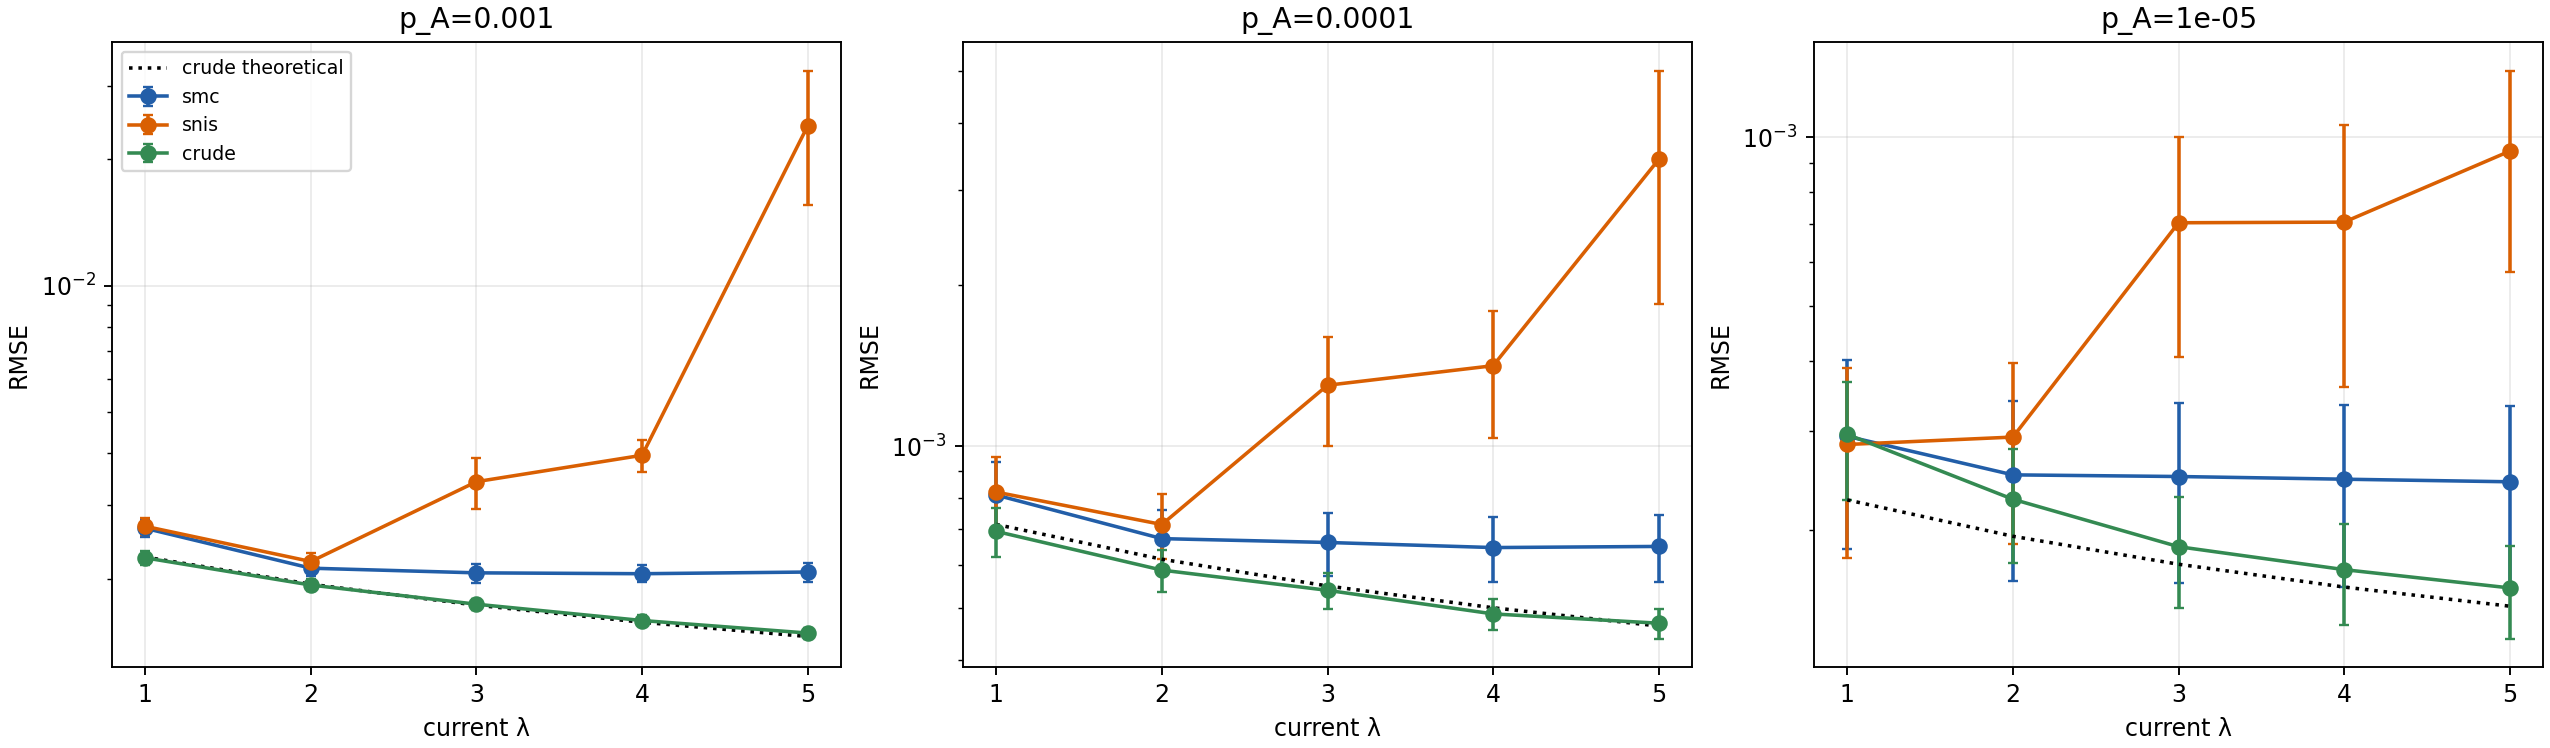

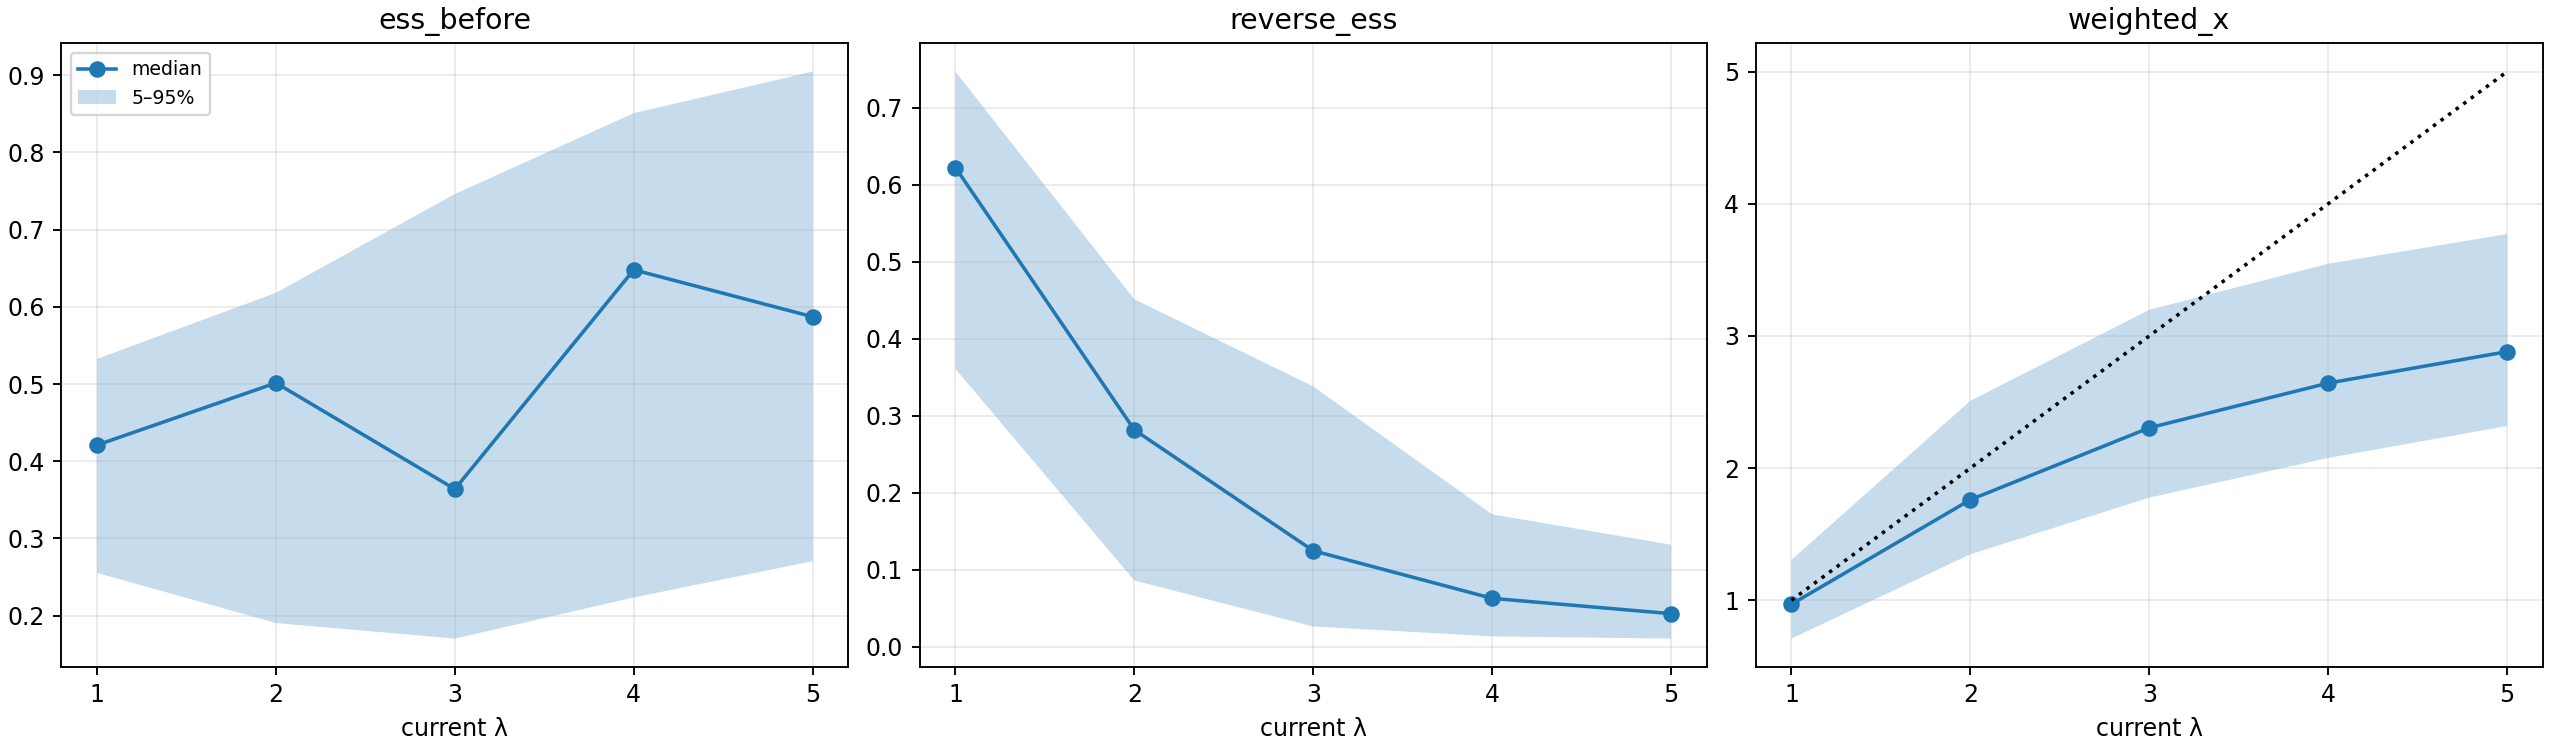

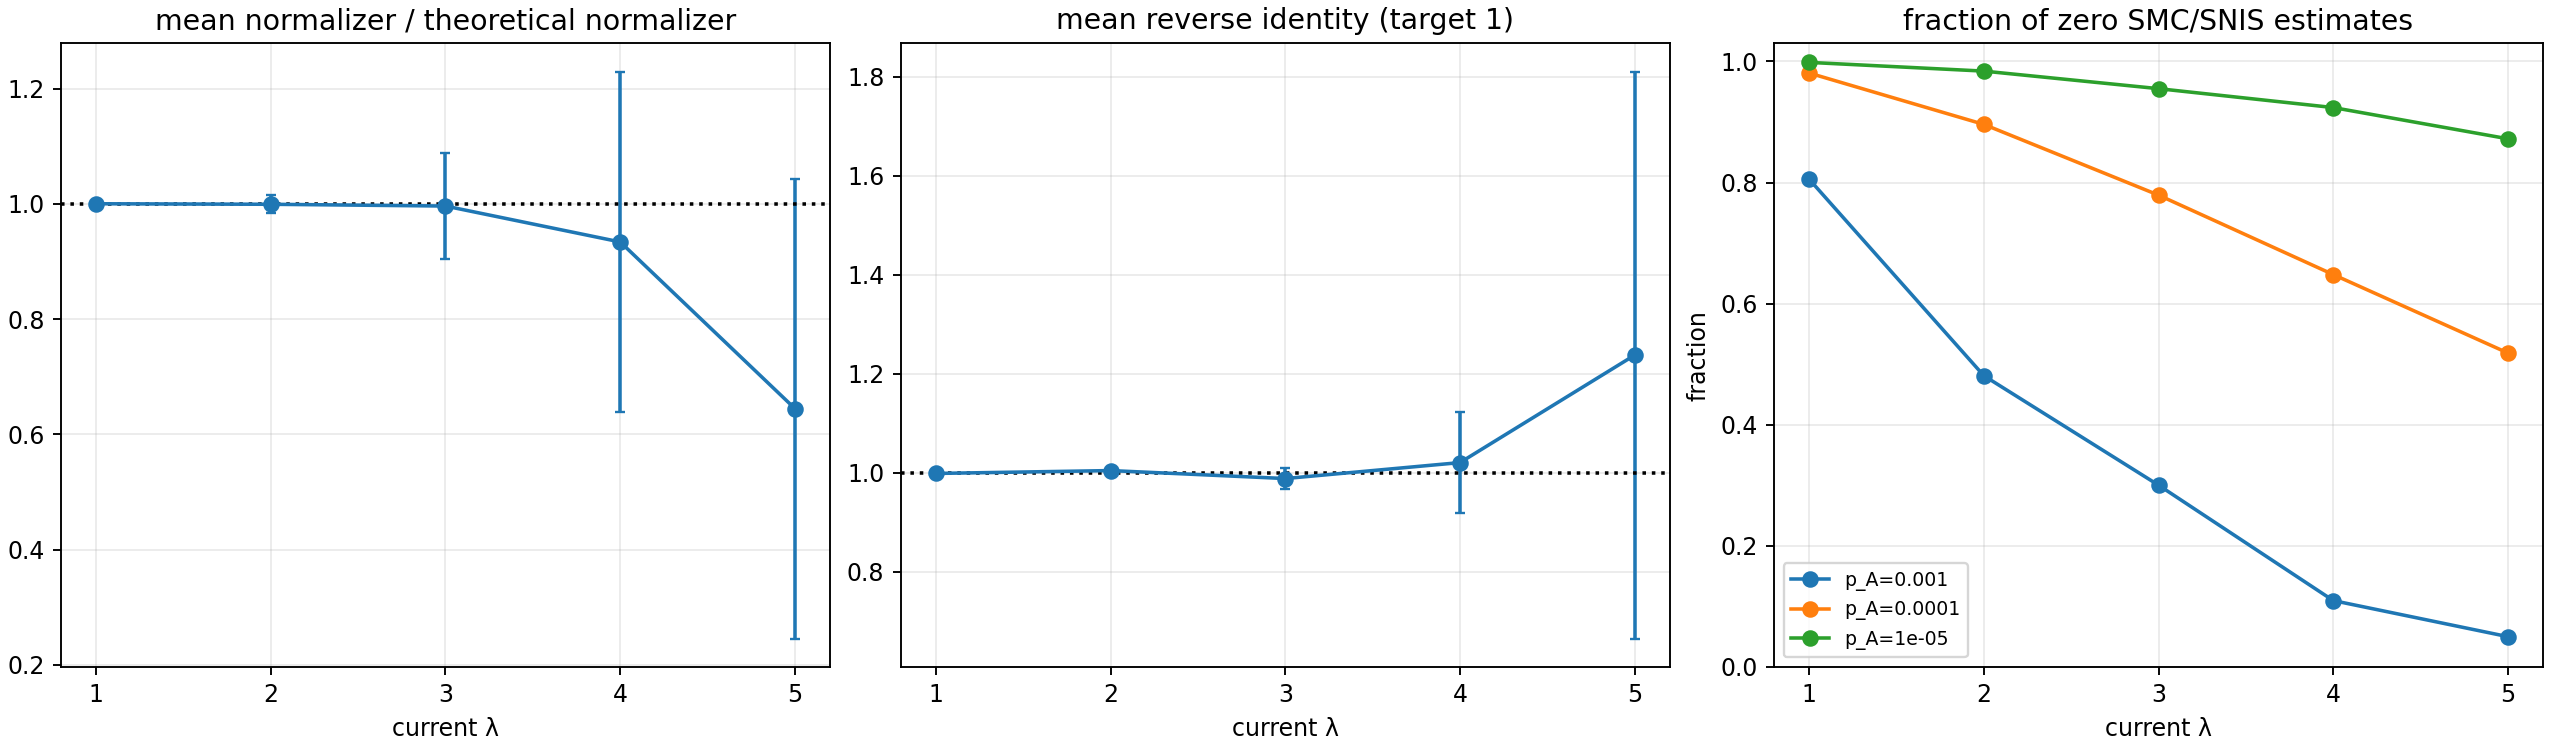

CSV and figures: C:\Users\UTENTE\AppData\Local\Temp\five_level_notebook_o1ec9gcc\empty_working_directory\five_level_results


In [6]:
from IPython.display import display, Image
display(summary[['level','p_A','estimator','mean','bias','bias_mc_se','variance','rmse','rmse_mc_se','zero_fraction','budget_transitions_mean','crude_theoretical_rmse']])
display(summary_by_seed[['main_seed','level','p_A','estimator','bias','rmse','zero_fraction']])
display(diagnostic)
display(pd.read_csv(OUT/'diagnostics_by_seed.csv'))
display(Image(filename=str(OUT/'rmse_equal_transitions.png')))
display(Image(filename=str(OUT/'diagnostics.png')))
display(Image(filename=str(OUT/'weight_checks_and_zeros.png')))
print('CSV and figures:', OUT.resolve())

The plotted error bars on empirical RMSE and diagnostic means are approximate $\pm1.96$ Monte Carlo standard errors across **independent whole runs**; they do not account for heavy-tail uncertainty beyond the observed runs. The exact crude curve uses $\sqrt{p_A(1-p_A)/n}$ for each matched number $n$ of complete trajectories. Check each seed's results when a metric is driven by rare extreme estimates.